> **Versão pública (2026).** Notebook original, executado no Google Colab, com os dados numa pasta do Google Drive (`<PASTA_DO_PROJETO>`). As saídas são as originais. Veja o [README desta pasta](README.md).

In [1]:
%%sh
pip install pygad

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 2.7 MB/s eta 0:00:00


In [64]:
import numpy as np
import pandas as pd

import pygad
import tensorflow as tf
import pygad.kerasga

import matplotlib.pyplot as plt

# Lê Dataset (Conectar antes ao Google Drive)

In [4]:
path = '<PASTA_DO_PROJETO>/'

In [5]:
df = pd.read_csv(f'{path}/dados/spotify_songs.csv')

In [6]:
df.columns

Index(['track_id', 'track_name', 'track_artist', 'track_popularity',
       'track_album_id', 'track_album_name', 'track_album_release_date',
       'playlist_name', 'playlist_id', 'playlist_genre', 'playlist_subgenre',
       'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_ms'],
      dtype='object')

In [7]:
cols_id = ['track_id', 'track_name', 'track_artist']
col_time = 'track_album_release_date'
target = 'track_popularity'
features = ['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness',
            'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
cols_tot = np.concatenate([cols_id, [col_time], [target], features])
df = df[cols_tot]
df[col_time] = pd.to_datetime(df[col_time])
df = df.drop_duplicates()

In [8]:
display(df.sort_values('track_popularity', ascending = False).head().T)

1551                    20092  \
track_id                  2XU0oxnq2qxCpomAAuJY8K  696DnlkuDOXcMAnKlTgXXK   
track_name                          Dance Monkey                 ROXANNE   
track_artist                         Tones and I          Arizona Zervas   
track_album_release_date     2019-10-17 00:00:00     2019-10-10 00:00:00   
track_popularity                             100                      99   
danceability                               0.824                   0.621   
energy                                     0.588                   0.601   
[... 40 linhas omitidas na versão pública ...]
mode                                           1  
speechiness                               0.0629  
acousticness                             0.00147  
instrumentalness                        0.000209  
liveness                                  0.0938  
valence                                    0.345  
tempo                                    171.017  
duration_ms                               201573

# Normalização

In [9]:
df[target] = df[target]/100
for f in features:
    df[f] = (df[f] - df[f].mean())/df[f].std()

# Exemplo PyGAD

In [11]:
function_inputs = [4, -2, 3.5, 5, -11, -4.7]
desired_output = 44

def fitness_func(ga_instance, solution, solution_idx):
    output = np.sum(solution*function_inputs)
    fitness = 1.0 / np.abs(output - desired_output)
    return fitness

fitness_function = fitness_func

num_generations = 50
num_parents_mating = 4

sol_per_pop = 8
num_genes = len(function_inputs)

init_range_low = -2
init_range_high = 5

parent_selection_type = "sss"
keep_parents = 1

crossover_type = "single_point"

mutation_type = "random"
mutation_percent_genes = 10

ga_instance = pygad.GA(num_generations=num_generations,
                       num_parents_mating=num_parents_mating,
                       fitness_func=fitness_function,
                       sol_per_pop=sol_per_pop,
                       num_genes=num_genes,
                       init_range_low=init_range_low,
                       init_range_high=init_range_high,
                       parent_selection_type=parent_selection_type,
                       keep_parents=keep_parents,
                       crossover_type=crossover_type,
                       mutation_type=mutation_type,
                       mutation_percent_genes=mutation_percent_genes)

ga_instance.run()

In [12]:
solution, solution_fitness, solution_idx = ga_instance.best_solution()
print("Parameters of the best solution : {solution}".format(solution=solution))
print("Fitness value of the best solution = {solution_fitness}".format(solution_fitness=solution_fitness))

prediction = np.sum(np.array(function_inputs)*solution)
print("Predicted output based on the best solution : {prediction}".format(prediction=prediction))

Parameters of the best solution : [ 4.3233973   5.23629228  4.63583355  3.17634717 -0.74185737  0.66232556]
Fitness value of the best solution = 41.08273574616965
Predicted output based on the best solution : 43.97565887514944


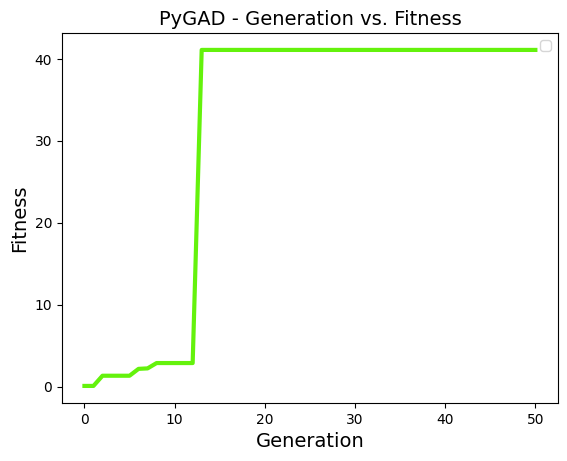

In [13]:
ga_instance.plot_fitness()
plt.show()

# PyGAD + TensorFlow

In [80]:
#Arquitetura da Rede Neural

nome = 'nn'
x_shape = len(features)
y_shape = 1

camada_entrada = tf.keras.layers.Input(shape = x_shape, name = f'{nome}_input')
lista_camadas = [camada_entrada]
lista_neuronios = [8, 4, 2]
for i in range(0, len(lista_neuronios)):
    n = lista_neuronios[i]
    lista_camadas.append(tf.keras.layers.Dense(n, activation = 'relu', name = f'{nome}_dense{str(i)}')(lista_camadas[-1]))
camada_saida = tf.keras.layers.Dense(y_shape, activation = 'sigmoid', name = f'{nome}_output')(lista_camadas[-1])
modelo = tf.keras.models.Model(inputs = camada_entrada, outputs = camada_saida, name = 'model')
modelo_config = modelo.to_json()

modelo.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 nn_input (InputLayer)       [(None, 12)]              0         
                                                                 
 nn_dense0 (Dense)           (None, 8)                 104       
                                                                 
 nn_dense1 (Dense)           (None, 4)                 36        
                                                                 
 nn_dense2 (Dense)           (None, 2)                 10        
                                                                 
 nn_output (Dense)           (None, 1)                 3         
                                                                 
Total params: 153 (612.00 Byte)
Trainable params: 153 (612.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [98]:
#Define uma população inicial

num_population = 20

#Gera a população inicial com pesos aleatórios
keras_ga = pygad.kerasga.KerasGA(model = modelo,
                                 num_solutions = num_population)
initial_population = keras_ga.population_weights

In [99]:
#Definição da função de Fitness

def set_neural_network(solution):
    global modelo_config
    modelo_temp = tf.keras.models.model_from_json(modelo_config)
    solution_matrix = pygad.kerasga.model_weights_as_matrix(model = modelo_temp, weights_vector = solution)
    modelo_temp.set_weights(weights = solution_matrix)
    return modelo_temp

def fitness_calc(targets, predicoes):
    #Calcula o fitness das predições
    loss_func = tf.keras.losses.MeanSquaredError()
    std_target = targets.std()**2
    solution_fitness = 1 - loss_func(targets, predicoes).numpy()/std_target
    return solution_fitness

def fitness_func(ga_instance, solution, sol_idx):
    global df, target, features
    #Pega os pesos da solução proposta a atribui a arquitetura da rede
    modelo_temp = set_neural_network(solution)
    #Faz as predições
    predicoes = modelo_temp.predict(df[features], verbose = False)
    #Calcula a função de fitness
    solution_fitness = fitness_calc(df[target], predicoes)
    return solution_fitness

fitness_func(ga_instance = None, solution = initial_population[0], sol_idx = None)

-0.36712582782242276

In [106]:
#Define uma função de callback (opcional)

def callback_generation(ga_instance):
    #OBS: note que o ga_instance.best_solution() é uma chamada de função que exige o calculo do fitness de toda a população
    #(insto é, do jeito que está programado, o plot pode exigir muito pode computacional)
    print('Generation = {generation}'.format(generation = ga_instance.generations_completed))
    if ga_instance.last_generation_fitness is None:
        print('Fitness = {fitness}'.format(fitness = ga_instance.best_solution()[1]))
    else:
        print('Fitness = {fitness}'.format(fitness = max(ga_instance.last_generation_fitness)))

In [107]:
num_generations = 50
num_parents_mating = 10
initial_population = keras_ga.population_weights

def cria_modelo_populacao(population):
    global modelo_config
    input_compartilhado = tf.keras.models.model_from_json(modelo_config).input
    lista_modelos_populacao = [set_neural_network(solution) for solution in list(population)]
    lista_layers_finais_populacao = []
    for i in range(0, len(lista_modelos_populacao)):
        modelo_temp = lista_modelos_populacao[i]
        modelo_temp._name = modelo_temp.name + f'_{i}'
        layer_final_temp = modelo_temp(input_compartilhado) #adiciona o Input Compartilhado
        lista_layers_finais_populacao.append(layer_final_temp)
    camada_concatenada_output = tf.keras.layers.Concatenate()([v.output for v in lista_modelos_populacao])
    modelo_populacao = tf.keras.models.Model(inputs = input_compartilhado, outputs = lista_layers_finais_populacao)
    return modelo_populacao

class GPU_GA(pygad.GA):
    def cal_pop_fitness(self):
        global df, target, features
        modelo_populacao = cria_modelo_populacao(self.population)
        predicoes_populacao = modelo_populacao.predict(df[features], verbose = False)
        pop_fitness = np.array([fitness_calc(df[target], predicoes) for predicoes in predicoes_populacao])
        return pop_fitness

ga_instance = GPU_GA(num_generations = num_generations,
                     num_parents_mating = num_parents_mating,
                     initial_population = initial_population,
                     fitness_func = fitness_func,
                     on_generation = callback_generation)

In [108]:
callback_generation(ga_instance)
ga_instance.run()

Generation = 0
Fitness = -0.1726606134611921
Generation = 1
Fitness = -0.1623875334928191
Generation = 2
Fitness = -0.1623875334928191
Generation = 3
Fitness = -0.14805856097351522
[... 86 linhas omitidas na versão pública ...]
Generation = 47
Fitness = 1.1886928944160324e-05
Generation = 48
Fitness = 1.1886928944160324e-05
Generation = 49
Fitness = 1.2351096093543568e-05
Generation = 50
Fitness = 1.2351096093543568e-05


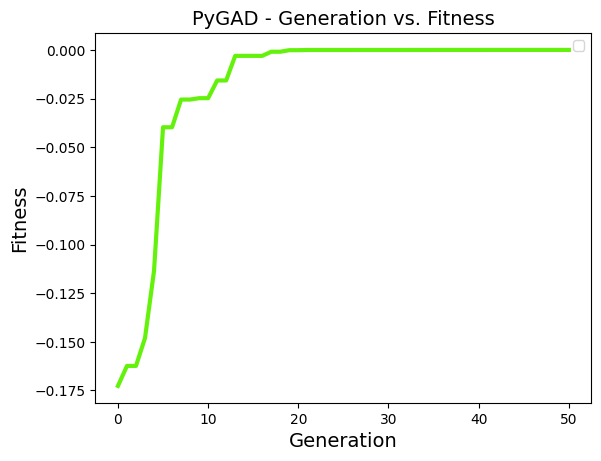

In [109]:
ga_instance.plot_fitness()
plt.show()